# Missing CpG features: effect on clock performance

Investigates how CpG coverage affects each clock's ability to predict its own target. Two complementary analyses are run:

**Analysis 1 — Synthetic masking curve.** Starting from fully-observed (at inference) samples, additional CpGs are progressively masked and per-clock MAE / Pearson r / R² is recorded at each level. This is a controlled experiment: all variation comes from the masking, not sample differences.

**Analysis 2 — Real coverage bins.** Samples are grouped by their actual observed CpG fraction in the data and performance is computed within each bin. This shows what happens in practice when arrays have genuinely missing probes.

Both analyses score each clock only against its own true labels (not cross-clock).

Helper functions live in `eval_utils.py`.

## Parameters
Set everything here, then run all cells.

In [1]:
from pathlib import Path
import numpy as np

# ── Which clocks ──────────────────────────────────────────────────
# None = "age" + every best_head_<clock>.pt found in HEAD_PATH
CLOCKS     = None

# ── Paths ─────────────────────────────────────────────────────────
ROOT          = Path("/work/gr-fe/bryan/EpiHydra")
DATA_PATH     = ROOT / "data/03_final/combined/methylation.pkl"
MODEL_PATH    = ROOT / "data/03_final/methylgpt/medium"
EPIHYDRA_PATH = ROOT / "results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750"
HEAD_PATH     = ROOT / "results/tensorboard/ckpt/clocks4_nlayers6_nhead4_emb256_lora_lr1e-04_bs32_mask0.15_heads4_20261105_072540"
LORA_CKPT     = EPIHYDRA_PATH / "best_model.pt"

# ── Model settings (must match training) ──────────────────────────
NUM_HEADS  = 4
LORA_R     = 16
LORA_ALPHA = 8

# ── Data split ────────────────────────────────────────────────────
SPLIT_RATIOS = dict(train_ratio=None, valid_ratio=None, test_ratio=None)
BATCH_SIZE   = 16
RANDOM_STATE = 42

# ── Analysis 1: synthetic masking curve ───────────────────────────
# Fractions of CpGs to additionally mask on top of real missingness
MASK_FRACTIONS = np.round(np.arange(0.0, 1.0, 0.1), 2).tolist()

# ── Analysis 2: real coverage bins ────────────────────────────────
N_COVERAGE_BINS = 5    # number of equal-width bins from 0 % to 100 %
MIN_BIN_SAMPLES = 3    # bins with fewer samples are dropped

# ── Output ────────────────────────────────────────────────────────
SAVE_DIR = None        # Path to save figures, or None

## Imports

In [2]:
import json
import pickle
import warnings

# Silence noisy but harmless library warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*flash_attn.*")
warnings.filterwarnings("ignore", message=".*nested tensor.*")

import matplotlib.pyplot as plt
import torch
import pandas as pd

%matplotlib inline

from methylgpt import MethylGPTModel, MethylVocab
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value
from evaluation import eval_utils as eu 
from epihydra import VocabWrapper, build_multiclock_dataloaders, evaluate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
clock_names = eu.resolve_clocks(CLOCKS, HEAD_PATH)

print(f"Using device: {device}")
print(f"Evaluating clocks: '{clock_names}'")

Using device: cuda
Evaluating clocks: '['age', 'grimageadapter_age', 'hannum_age', 'horvath_age', 'phenoage_age']'


## Load data, config and vocab

In [3]:
print("Loading data...")
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f)

with open(MODEL_PATH / "args.json") as f:
    pretrain_config = json.load(f)

vocab = VocabWrapper(MODEL_PATH / "vocab.json", pretrain_config["n_hvg"])

Loading data...


## Build dataloaders
Saved training scalers are reused where available. Any clock without one (typically `"age"`) gets a fresh scaler fitted on this training split.

In [4]:
scalers = eu.load_scalers(HEAD_PATH)

dataloader = build_multiclock_dataloaders(
    data         = data,
    vocab        = vocab,
    clock_names  = clock_names,
    batch_size   = BATCH_SIZE,
    num_workers  = 0,
    random_state = RANDOM_STATE,
    verbose      = True,
    scalers      = scalers,   # reused where available, fitted otherwise
    **SPLIT_RATIOS,
)
scalers = dataloader["scalers"]         # the scalers actually used, one per clock

Samples in meta : 1743
Samples in CpG  : 1743
Common samples  : 1743
Samples after drop : 1743
  age                 : 1743 labeled
  grimageadapter_age  : 1743 labeled
  hannum_age          : 1743 labeled
  horvath_age         : 1743 labeled
  phenoage_age        : 1743 labeled

Vocab CpGs : 49,159 | Present : 21,825 (44.4%) | Missing : 27,334
ℹ  age                 : scaler fitted on all values (no-split mode).
ℹ  grimageadapter_age  : reusing supplied pre-fitted scaler.
ℹ  hannum_age          : reusing supplied pre-fitted scaler.
ℹ  horvath_age         : reusing supplied pre-fitted scaler.
ℹ  phenoage_age        : reusing supplied pre-fitted scaler.
✓ Single multi-clock loader built (1743 samples, no masking).



## Build the multi-clock model
Frozen, LoRA-merged backbone + one trained head per clock.

In [5]:
model = eu.build_multiclock_model(
    MODEL_PATH, vocab, pretrain_config,
    lora_ckpt   = LORA_CKPT,
    head_path   = HEAD_PATH,
    clock_names = clock_names,
    device      = device,
    num_heads   = NUM_HEADS,
    lora_r      = LORA_R,
    lora_alpha  = LORA_ALPHA,
)

I0000 00:00:1794208104.916632 3338279 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794208110.182726 3338279 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794208130.481913 3338279 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: U

Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/medium-best_model_epoch6.pt

Loading frozen LoRA adapters from /work/gr-fe/bryan/EpiHydra/results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750/best_model.pt
  source run   : nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750
  source epoch : 85  (valid MAE 4.864)
  lora_r=16 lora_alpha=8 targets=['Wqkv', 'out_proj', 'linear1', 'linear2']
  adapter tensors in checkpoint : 52
  adapter tensors in model      : 52 (lora_A + lora_B pairs)
  lora_B with non-zero weights  : 26/26
  adapters merged into base weights

  loaded head age                  <- best_model.pt
  loaded head grimageadapter_age   <- best_head_grimageadapter_age.pt (epoch 46)
  loaded head hannum_age           <- best_head_hannum_age.pt (epoch 47)
  loaded head horvath_age          <- best_head_horvath_age.pt (epoch 31)
  loaded head phenoage_age         <- best_head_phenoage_age.p

## Baseline predictions (no extra masking)
Establish the unmasked performance on the chosen split before introducing synthetic missingness. The loader is rebuilt unshuffled so rows stay aligned to sample IDs.

In [6]:
loader = eu.ordered_loader(dataloader['loader'])
ids    = dataloader[f"df"].index
predictions  = eu.predict_multiclock(model, loader, scalers, device, clock_names, ids)

print(f"{len(predictions)} samples x {len(clock_names)} clocks")

1743 samples x 5 clocks


In [7]:
# Baseline per-clock metrics (pred vs. true for the same clock only)
baseline_rows = []
for name in clock_names:
    sub = predictions[[f"{name}_pred", f"{name}_true"]].dropna()
    p, t = sub.iloc[:, 0].to_numpy(), sub.iloc[:, 1].to_numpy()
    if len(p) < 2:
        continue
    from scipy.stats import pearsonr
    from sklearn.metrics import r2_score
    baseline_rows.append({
        "clock"    : name,
        "n"        : len(p),
        "mae"      : round(float(np.mean(np.abs(p - t))), 3),
        "pearson_r": round(float(pearsonr(p, t)[0]), 3),
        "r2"       : round(float(r2_score(t, p)), 3),
    })

baseline = pd.DataFrame(baseline_rows).set_index("clock")
print("Baseline performance (0 % extra masking)")
display(baseline)

Baseline performance (0 % extra masking)


,n,mae,pearson_r,r2
clock,,,,
age,1743,7.278,0.946,0.849
grimageadapter_age,1743,15.772,-0.204,-1.487
hannum_age,1743,10.331,0.495,-1.092
horvath_age,1743,6.131,0.957,0.862
phenoage_age,1743,11.174,0.907,0.644


## Analysis 1 — Synthetic masking curve

For each masking fraction, the same random seed is used so comparisons across levels reflect the masking, not sample variation. The 0 % row should match the baseline above.

In [8]:
mask_results = eu.evaluate_missing_fraction(
    model, loader, scalers, device,
    clock_names    = clock_names,
    mask_fractions = MASK_FRACTIONS
)

print(mask_results.round(3).to_string(index=False))

             clock  mask_frac    n    mae  pearson_r     r2
               age        0.0 1743  7.277      0.946  0.849
grimageadapter_age        0.0 1743 15.771     -0.204 -1.487
        hannum_age        0.0 1743 10.331      0.495 -1.092
       horvath_age        0.0 1743  6.130      0.957  0.862
      phenoage_age        0.0 1743 11.175      0.907  0.644
               age        0.1 1743  7.448      0.943  0.840
grimageadapter_age        0.1 1743 15.929     -0.218 -1.497
        hannum_age        0.1 1743 10.547      0.497 -1.129
       horvath_age        0.1 1743  6.509      0.952  0.844
      phenoage_age        0.1 1743 11.540      0.903  0.616
               age        0.2 1743  7.790      0.937  0.821
grimageadapter_age        0.2 1743 15.971     -0.227 -1.462
        hannum_age        0.2 1743 10.637      0.500 -1.100
       horvath_age        0.2 1743  6.814      0.944  0.826
      phenoage_age        0.2 1743 12.032      0.895  0.580
               age        0.3 1743  8.00

In [9]:
mask_results.to_csv('/work/gr-fe/bryan/EpiHydra/results/mask_results.csv')

In [10]:
base = 1 - eu.compute_sample_coverage(dataloader["df"]).mean()
mask_results["total_missing"] = base + mask_results["mask_frac"] * (1 - base)

In [33]:
def plot_missing_fraction_curves(mask_results, metric="mae", clock_names=None,
                                 x="total_missing", ax=None, save_path=None):
    """
    Line per clock: performance vs. missing CpGs (evaluate_missing_fraction).

    x : "total_missing" — real + injected missingness (% of all vocab CpGs)
        "mask_frac"     — injected masking only (% of observed CpGs)
    """
    clock_names = clock_names or mask_results["clock"].unique().tolist()
    xlabel = {"total_missing": "Total CpGs missing (%)",
              "mask_frac":     "Additional CpGs masked (%)"}[x]

    with plt.rc_context(eu._NM_RC):
        if ax is None:
            fig, ax = plt.subplots(figsize=(89 * eu._MM, 70 * eu._MM), constrained_layout=True)
        else:
            fig = ax.figure

        cmap = plt.get_cmap("tab10")
        for i, name in enumerate(clock_names):
            sub = mask_results[mask_results["clock"] == name].sort_values(x)
            ax.plot(sub[x] * 100, sub[metric], marker="o", markersize=3,
                    lw=1.0, color=cmap(i), label=eu._clean(name))

        if x == "total_missing":
            base = mask_results["total_missing"].min()
            ax.axvline(base * 100, color="grey", lw=0.6, ls=":", zorder=0)
            ax.set_xlim(right=100)

        ax.set_xlabel(xlabel)
        ax.set_ylabel(eu._METRIC_LABEL[metric])
        ax.set_title("Clock performance vs. missing CpGs", pad=4, fontweight="bold")
        ax.legend(frameon=False, loc="best")
        if not eu._HIGH_IS_GOOD[metric]:
            ax.set_ylim(bottom=0)

    #_save(fig, save_path)
    return fig, ax

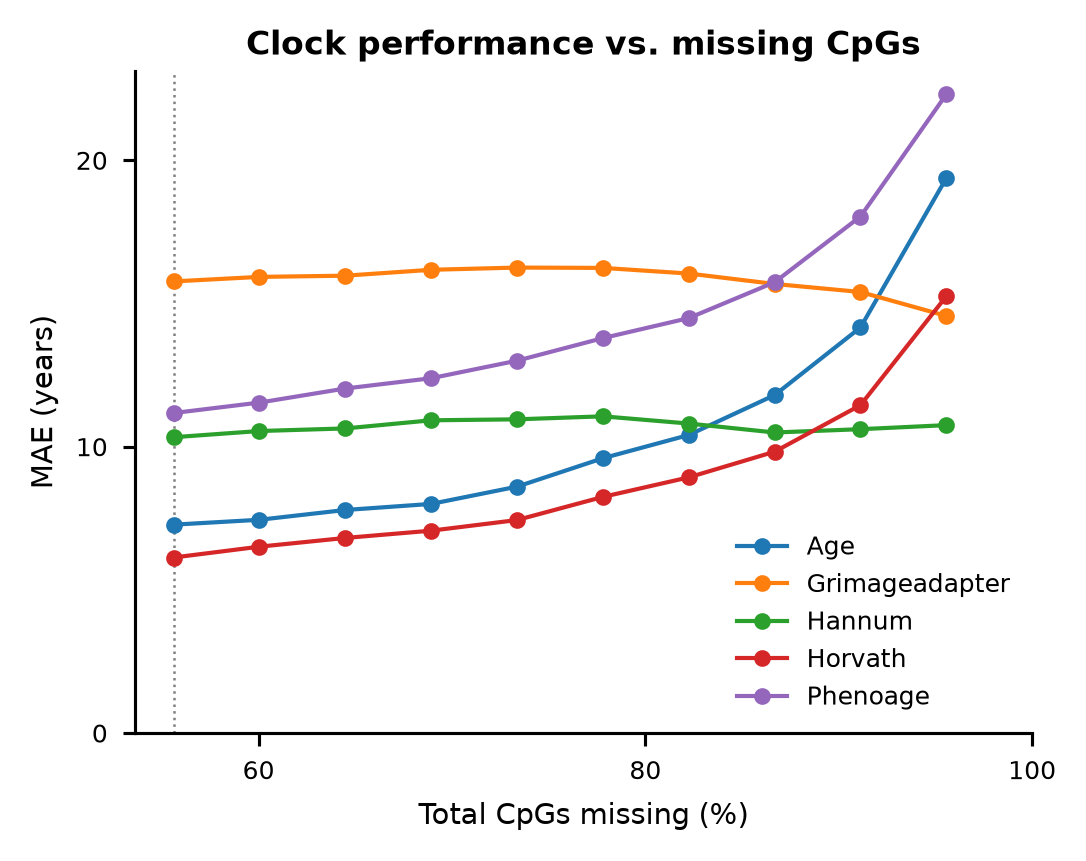

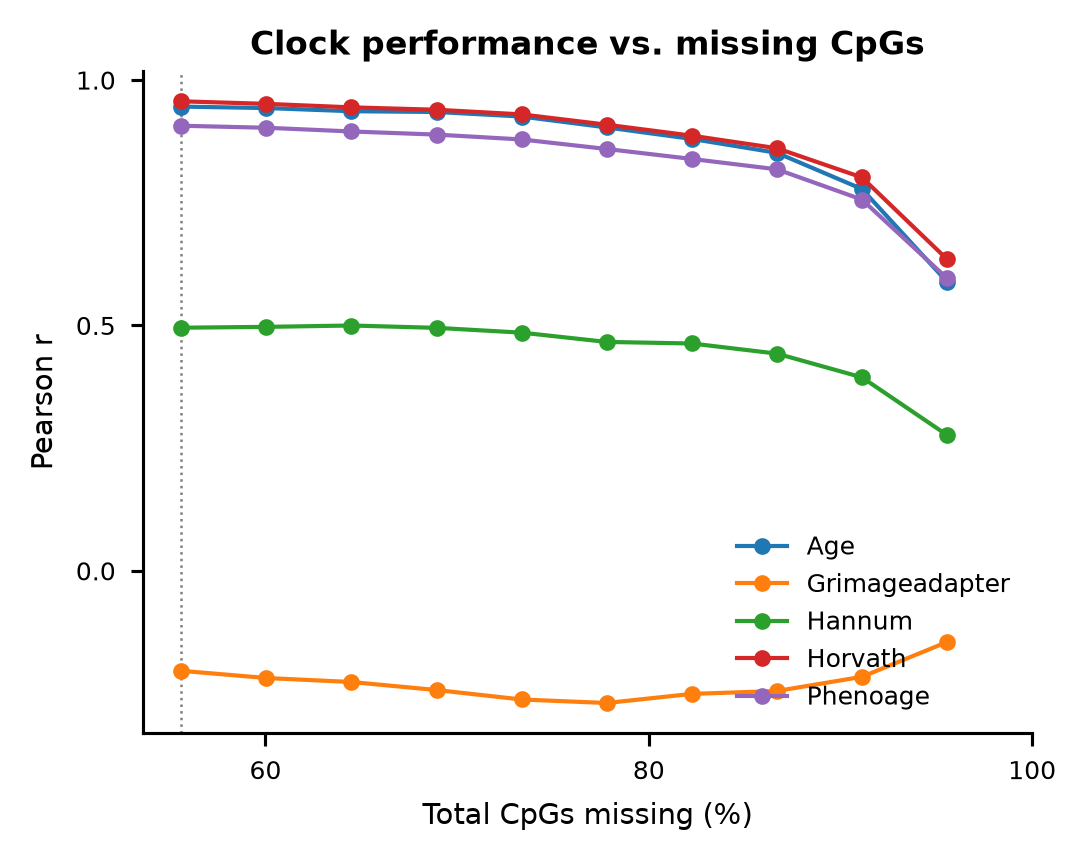

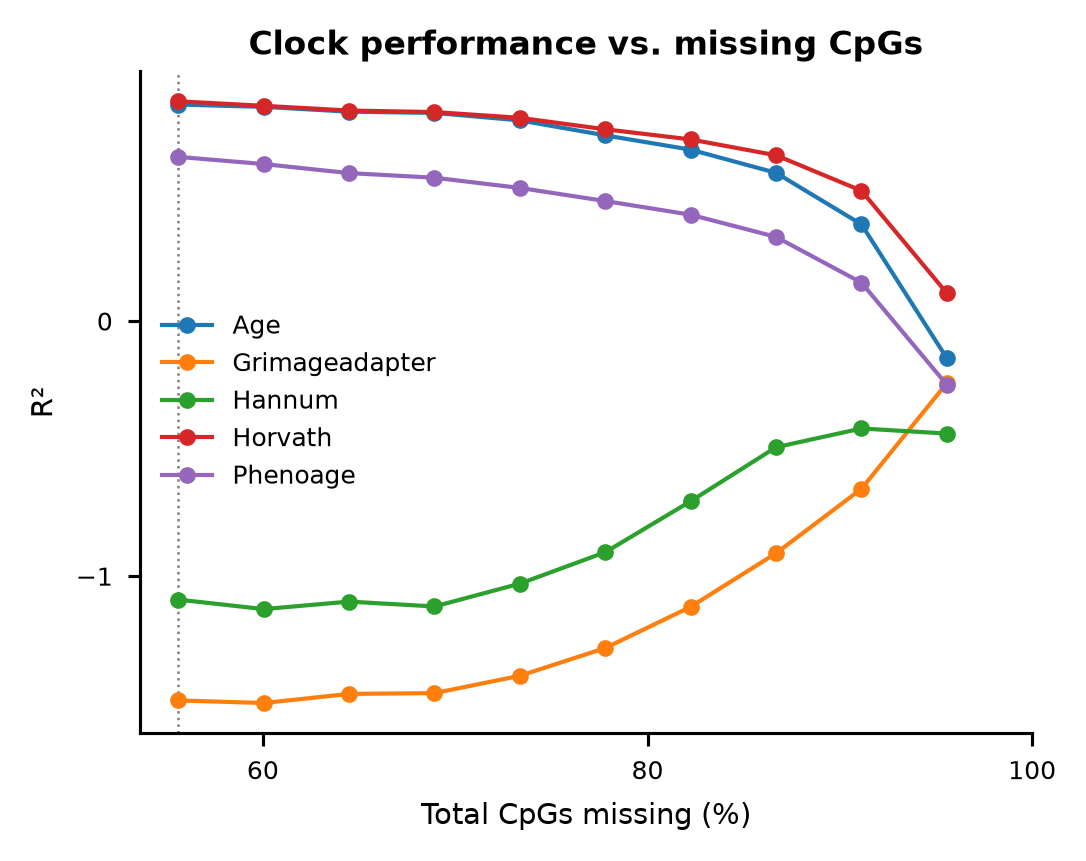

In [34]:
for metric in ("mae", "pearson_r", "r2"):
    fig, ax = plot_missing_fraction_curves(mask_results, metric=metric, x='total_missing',
                                               clock_names=clock_names, )
    if SAVE_DIR:
        fig.savefig(Path(SAVE_DIR) / f"masking_curve_{metric}.pdf")
        fig.savefig(Path(SAVE_DIR) / f"masking_curve_{metric}.png")

## Analysis 2 — Real CpG coverage bins

Each sample's coverage is the fraction of vocab CpGs that are non-NaN in the aligned data. Samples are binned by this fraction and per-clock performance is computed within each bin, using only samples that have a true label for that clock.

In [19]:
coverage_df = eu.compute_sample_coverage(dataloader["df"])

print("Coverage distribution:")
print(coverage_df.describe().round(3))

Coverage distribution:
count    1743.000
mean        0.444
std         0.000
min         0.444
25%         0.444
50%         0.444
75%         0.444
max         0.444
Name: cpg_coverage, dtype: float64


In [22]:
coverage_results = eu.coverage_performance(
    predictions, coverage_df, clock_names,
    n_bins      = N_COVERAGE_BINS,
    min_samples = MIN_BIN_SAMPLES,
)
display(coverage_results.round(3))

,clock,coverage_bin,coverage_mid,n,mae,pearson_r,r2
0,age,40%–60%,0.5,1743,7.278,0.946,0.849
1,grimageadapter_age,40%–60%,0.5,1743,15.772,-0.204,-1.487
2,hannum_age,40%–60%,0.5,1743,10.331,0.495,-1.092
3,horvath_age,40%–60%,0.5,1743,6.131,0.957,0.862
4,phenoage_age,40%–60%,0.5,1743,11.174,0.907,0.644


/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


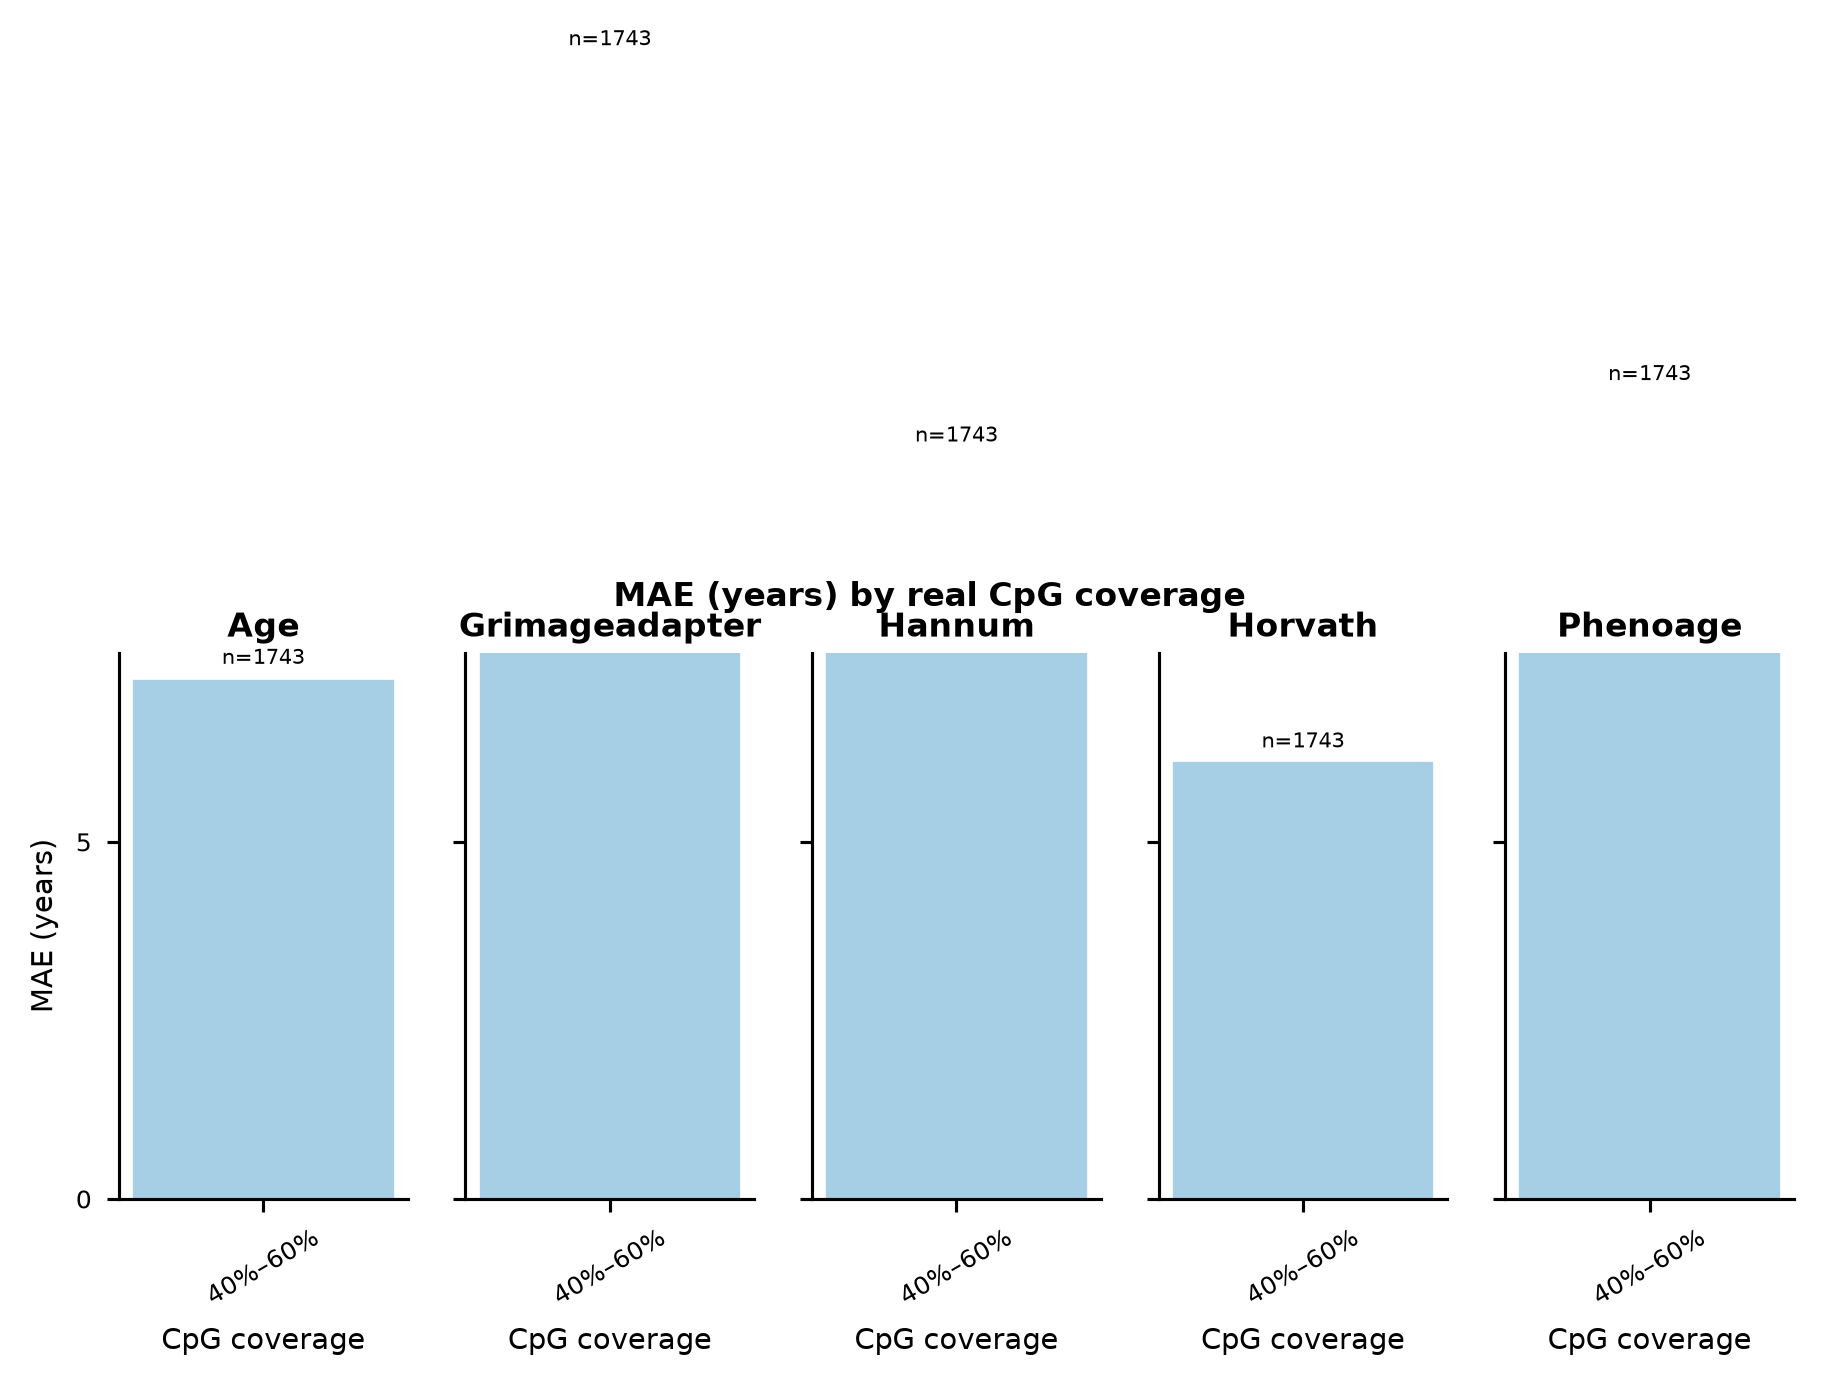

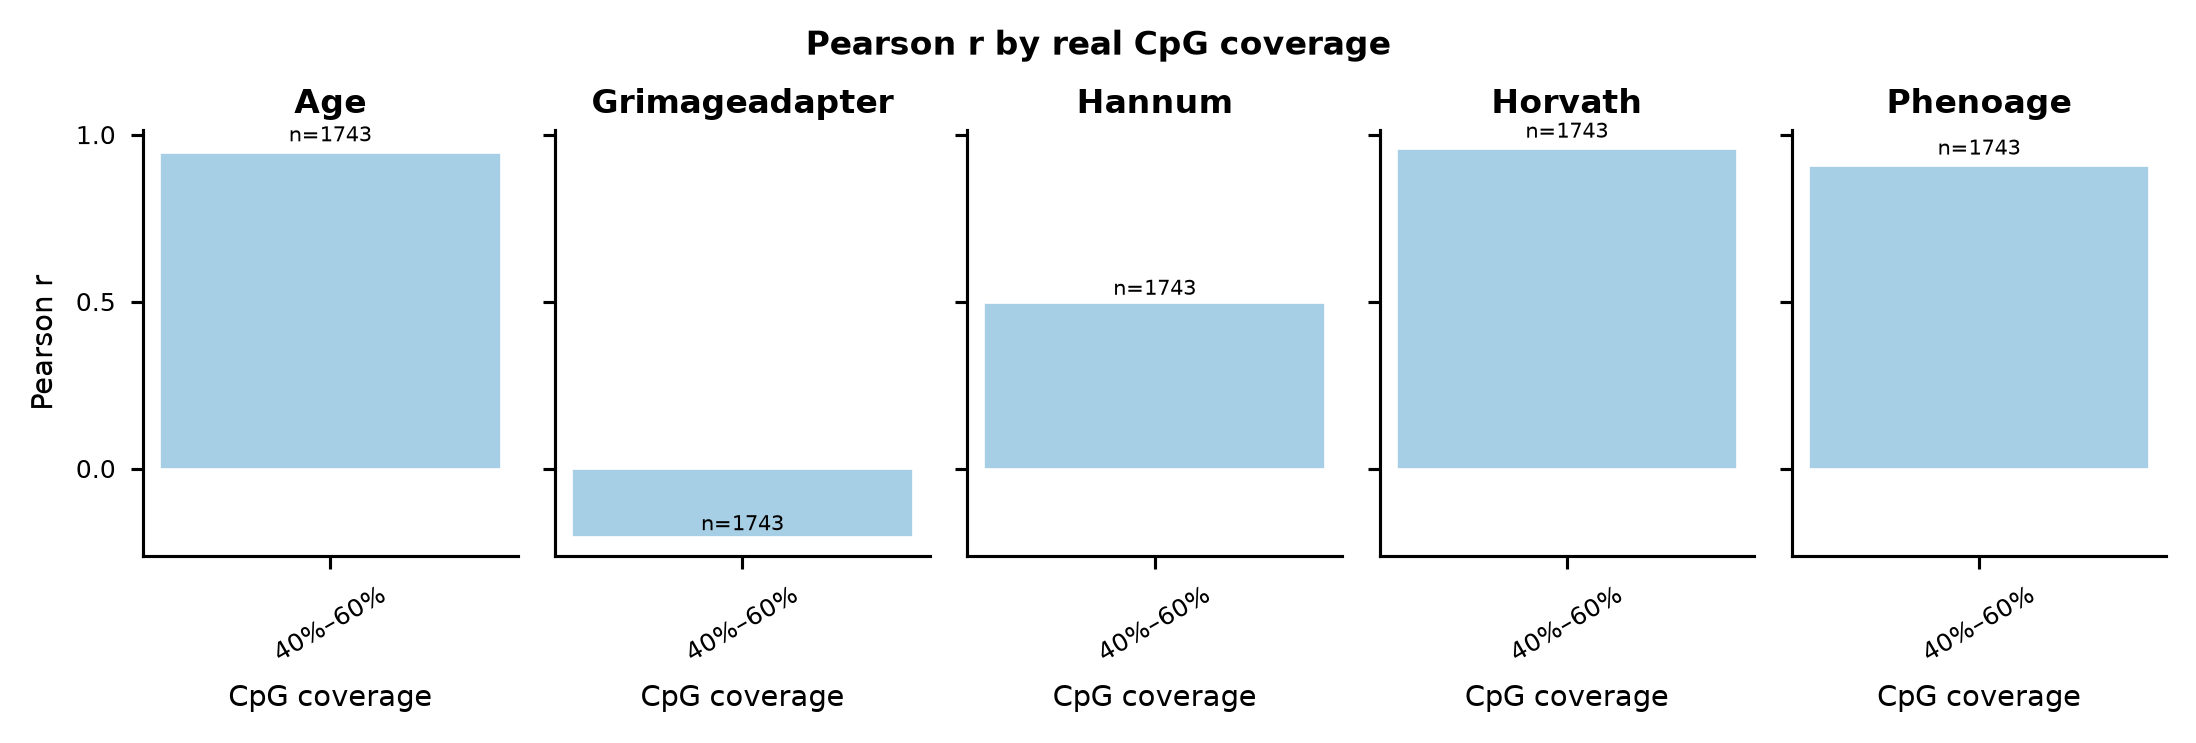

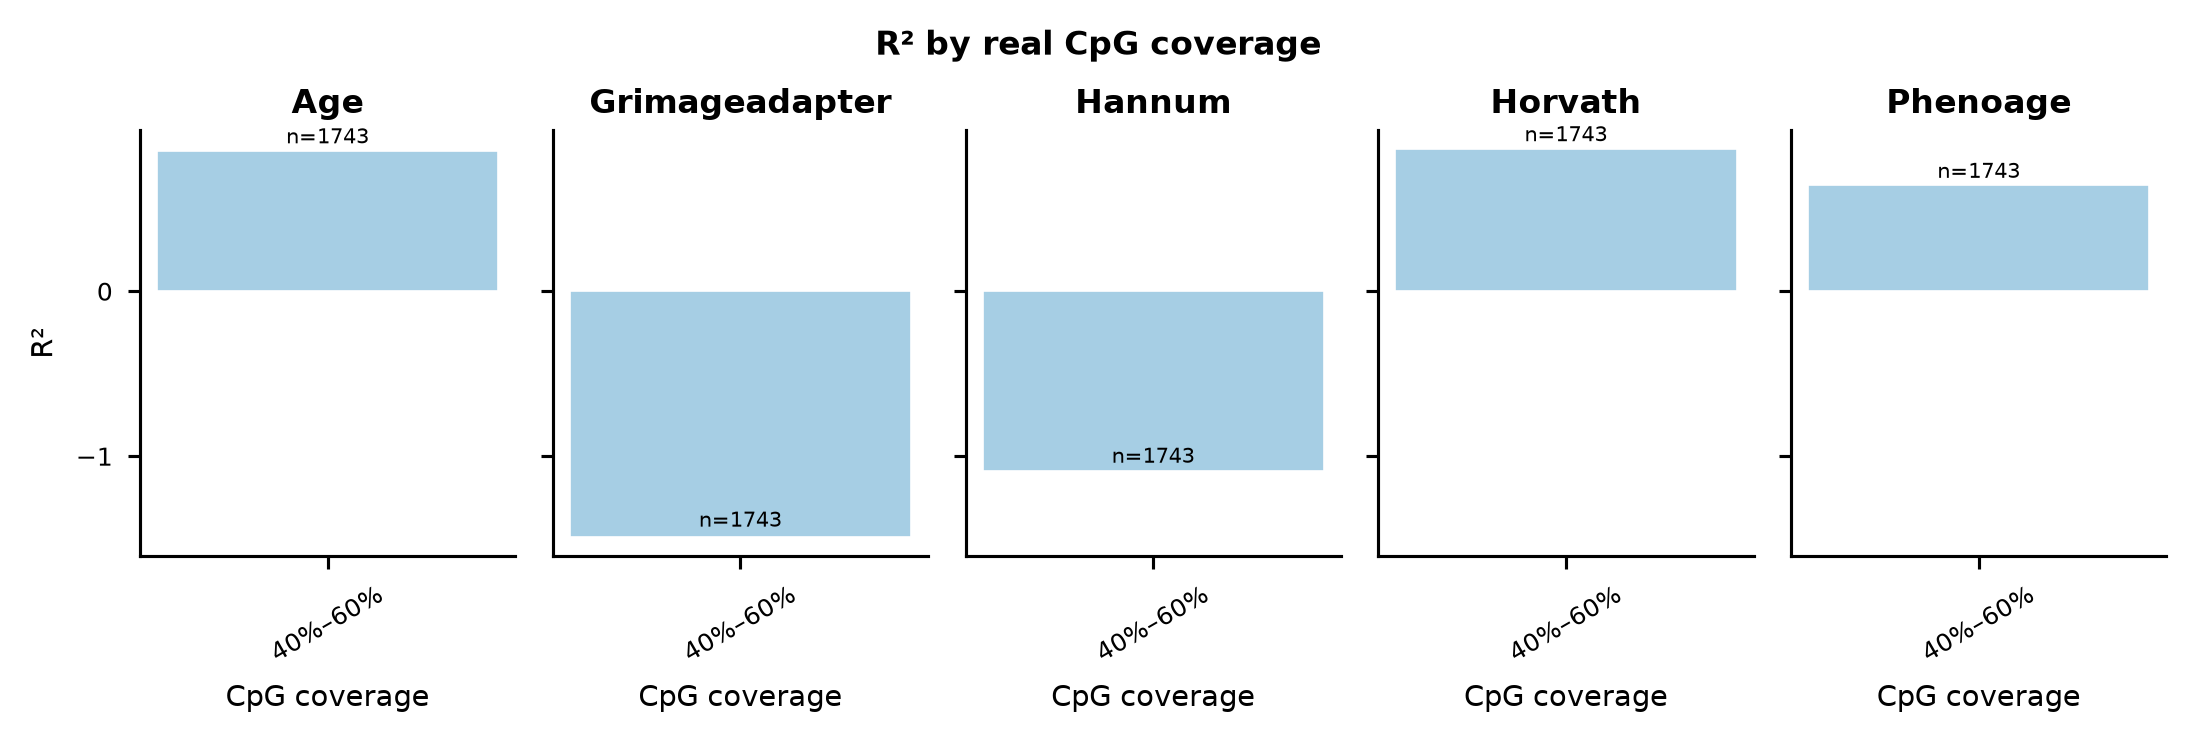

In [23]:
for metric in ("mae", "pearson_r", "r2"):
    fig, axes = eu.plot_coverage_performance(coverage_results, metric=metric,
                                              clock_names=clock_names)
    if SAVE_DIR:
        fig.savefig(Path(SAVE_DIR) / f"coverage_bins_{metric}.pdf")
        fig.savefig(Path(SAVE_DIR) / f"coverage_bins_{metric}.png")
    plt.show()

## Summary: baseline vs. high missingness

Compare baseline (0 % extra masking) to the most heavily masked level, so the cost of missingness is immediately visible.

In [25]:
worst_frac = max(MASK_FRACTIONS)
worst      = mask_results[mask_results["mask_frac"] == worst_frac].set_index("clock")

summary = baseline[["mae", "pearson_r", "r2"]].copy()
summary.columns = [f"baseline_{c}" for c in summary.columns]
for metric in ("mae", "pearson_r", "r2"):
    summary[f"masked_{metric}"] = worst[metric]
    delta = summary[f"masked_{metric}"] - summary[f"baseline_{metric}"]
    summary[f"delta_{metric}"] = delta.round(3)

display(summary.round(3))

,baseline_mae,baseline_pearson_r,baseline_r2,masked_mae,delta_mae,masked_pearson_r,delta_pearson_r,masked_r2,delta_r2
clock,,,,,,,,,
age,7.278,0.946,0.849,19.377,12.099,0.589,-0.357,-0.145,-0.994
grimageadapter_age,15.772,-0.204,-1.487,14.566,-1.206,-0.145,0.059,-0.243,1.244
hannum_age,10.331,0.495,-1.092,10.752,0.421,0.277,-0.218,-0.441,0.651
horvath_age,6.131,0.957,0.862,15.252,9.121,0.635,-0.322,0.110,-0.752
phenoage_age,11.174,0.907,0.644,22.302,11.128,0.596,-0.311,-0.249,-0.893
